In [6]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [10]:
#load data
df = pd.read_csv("StudentPerformanceFactors.csv")

In [13]:
#data understanding
print(df.head())

print("\nShape :",df.shape)

print("\nData type : ",df.dtypes)

print("\nMissing Value :", df.isnull().sum())

print("\nDuplicates : ",df.duplicated().sum())

print("\nStatistical Summary",df.describe)

   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level  \
0                         No            7               73              Low   
1                         No            8               59              Low   
2                        Yes            7               91           Medium   
3                        Yes            8               98           Medium   
4                        Yes            6               65           Medium   

  Internet_Access  Tutoring_Sessions Family_Income Teacher_Quality  \
0             Ye

In [17]:
#select reqi data
df = df[
    ["Hours_Studied","Exam_Score"]
].dropna()


In [18]:
#define x and y
X = df[["Hours_Studied"]]
y = df["Exam_Score"]

In [19]:
#corelation
correlation = X["Hours_Studied"].corr(y)
print("\nCorrelation : ",correlation)


Correlation :  0.4454549540752822


In [28]:
#train - test split
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

In [29]:
#create model
model = LinearRegression()

In [30]:
#train model
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [31]:
#predict
y_pred = model.predict(X_test)

In [32]:
#model parameters
coefficient = model.coef_[0]
intercept = model.intercept_

print("\nCoefficient:", coefficient)
print("Intercept:", intercept)

print(
    f"\nRegression Equation:\n"
    f"Exam Score = {intercept:.2f} + "
    f"({coefficient:.2f} × Hours Studied)"
)



Coefficient: 0.2856687444430867
Intercept: 61.511167469044246

Regression Equation:
Exam Score = 61.51 + (0.29 × Hours Studied)


In [35]:
#evaluation
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test,y_pred)

print("\nEvaluation:")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)


Evaluation:
MAE: 2.4475687452945643
MSE: 10.85592128879332
RMSE: 3.294832513010839
R²: 0.2319868674542106


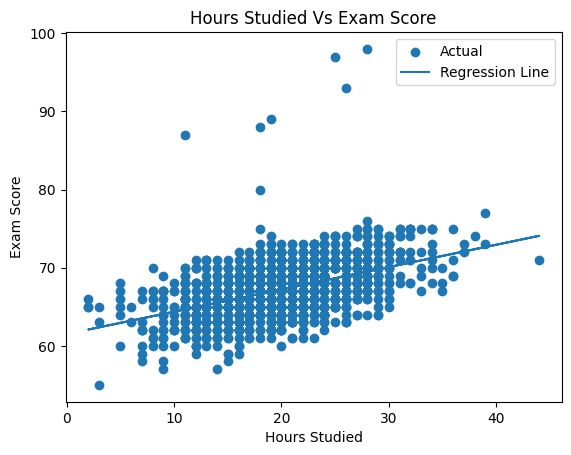

In [ ]:
#graph 1 : Actual data + regression line - to understand relationship + fitted line
plt.scatter(
    X_test,
    y_test,
    label = "Actual"
)

plt.plot(
    X_test,
    y_pred,
    label= "Regression Line"
)

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Hours Studied Vs Exam Score")
plt.legend()
plt.show()

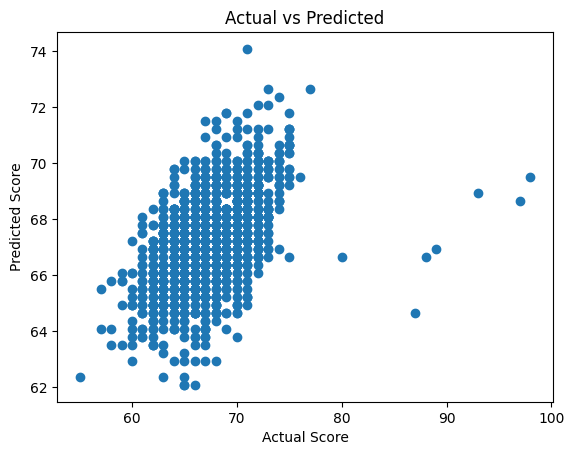

In [ ]:
#graph 2 : Actual vs predicted - to see how close predictions are to actual values
plt.scatter(
    y_test,
    y_pred
)

plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.title("Actual vs Predicted")

plt.show()

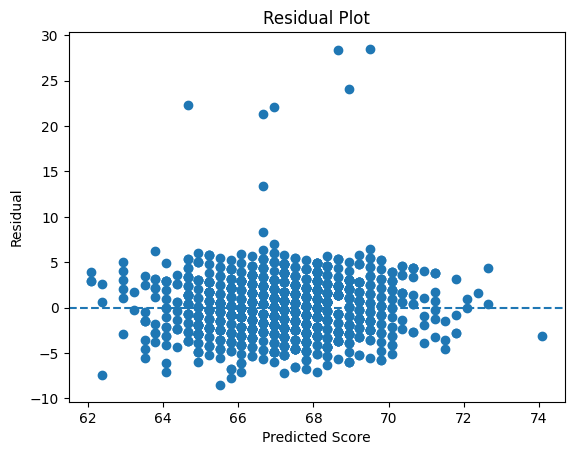

In [ ]:
#graph 3 : residual plot - to analyze the model's errors
residuals = y_test - y_pred

# Plot residuals against predicted values
plt.scatter(
    y_pred,
    residuals
)

# Reference line at residual = 0
plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Score")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()


In [42]:
#new prediction
new_student = pd.DataFrame({
    "Hours_Studied": [8.5]
})

prediction = model.predict(new_student)

print(
    "\nPredicted Exam Score for 8.5 hours:",
    prediction[0]
)


Predicted Exam Score for 8.5 hours: 63.939351796810485
